Test the slab model with 2 islands. Fig.15 (a):
$$
\begin{align*}
&m_1=m_2=1\;,\;n_1=-n_2=1\\
&\delta_1=\delta_2 =0.05\\
&\iota'=2
\end{align*}
$$

In [29]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
from fields.slab_bfield_two_pert import SlabBfieldTwoPert
from pyoculus.maps import ToroidalBfieldSection
from pyoculus.solvers import PoincarePlot, FixedPoint, Manifold
import matplotlib.pyplot as plt

#### Create the magnetic field:

In [2]:
field = SlabBfieldTwoPert(
    m1=1,
    n1=1,
    delta1=0.05,
    m2=1,
    n2=-1,
    delta2=0.05,
    iota_prime=2.0,
    x0=1.0,
)

xs1 = field.x0 + field.n1 / (field.iota_prime * field.m1)
xs2 = field.x0 + field.n2 / (field.iota_prime * field.m2)

print("The islands will be situated at x_s =", xs1, xs2)

The islands will be situated at x_s = 1.5 0.5


#### Create the map:

In [3]:
map = ToroidalBfieldSection(field, domain=[(0, 2), (0, 2*np.pi)])

#### Create Poincaré plot:

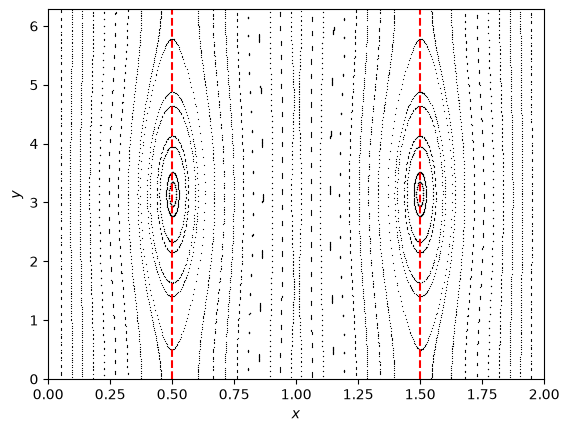

In [4]:
pplot = PoincarePlot.with_linspace(
    map,
    np.array([0.05, np.pi]),
    np.array([1.95, np.pi]),
    npts=50
)

# Follow each initial condition for 200 crossings
pplot.compute(npts=150)

# Plot directly in (x,y) coordinates
fig, ax = pplot.plot(plottype=None) # plottypeNone to directly plot in the coordinates of the map

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_xlim(0, 2)
ax.set_ylim(0, 2*np.pi)

ax.axvline(
    xs1,
    linestyle="--",
    label=rf"$x_s1={xs1:.3f}$",
    color="r"
)
ax.axvline(
    xs2,
    linestyle="--",
    label=rf"$x_s2={xs2:.3f}$",
    color="r"
)
plt.show()

#### Find fixed points:

(<Figure size 640x480 with 1 Axes>, <Axes: >)

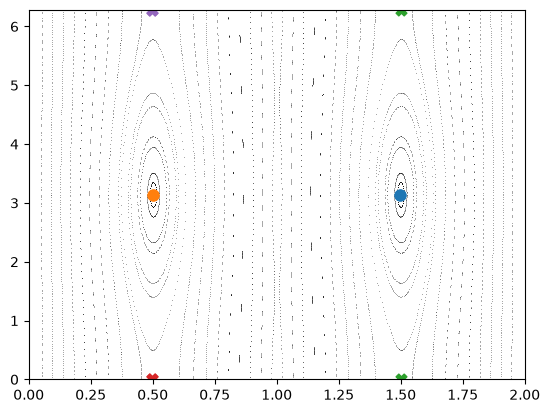

In [21]:
fig, ax = pplot.plot(
    marker=".",
    s=0.5,
    xlim=[0, 2],
    ylim=[0, 2*np.pi],
    plottype=None
)


fp = FixedPoint(map)

# Elliptic fixed points / O-points:
result = fp.find_with_iota(
    n = field.n1,
    m = field.m1,
    guess = np.array([1.4, 3]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

result = fp.find_with_iota(
    n = field.n2,
    m = field.m2,
    guess = np.array([1.4, 3]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

# Hyperbolic fixed points / X-points:
result = fp.find_with_iota(
    n = field.n1,
    m = field.m1,
    guess = np.array([1.4, 0.2]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

result = fp.find_with_iota(
    n = field.n2,
    m = field.m2,
    guess = np.array([0.4, 0.2]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

result = fp.find_with_iota(
    n = field.n2,
    m = field.m2,
    guess = np.array([0.6, 6.]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

In this case, the X-points have been found separately. All the fixed points have been found with ```find_with_iota()```.

#### Find manifolds

In [27]:
fp1 = FixedPoint(map)
fp1.find_with_iota(n = field.n1, m = field.m1, guess = np.array([1.4, 0.2]), method="scipy.root")   

fp2 = FixedPoint(map)
fp2.find_with_iota(n = field.n1, m = field.m1, guess = fp1.coords[1], method="scipy.root")  

fp3 = FixedPoint(map)
fp3.find_with_iota(n = field.n2, m = field.m2, guess = np.array([0.5, 0.2]), method="scipy.root")  

fp4 = FixedPoint(map)
fp4.find_with_iota(n = field.n2, m = field.m2, guess = np.array([0.6, 6]), method="scipy.root")  

ofp1 = FixedPoint(map)
ofp1.find_with_iota(n = field.n1, m = field.m1, guess = np.array([1.4, 3]), method="scipy.root")

ofp2 = FixedPoint(map)
ofp2.find_with_iota(n = field.n2, m = field.m2, guess = np.array([0.4, 3]), method="scipy.root")

In [42]:
manifold1 = Manifold(
    map, fp1, fp2,
    dir1=ofp1.coords[0] - fp1.coords[0],
    dir2=ofp1.coords[0] - fp2.coords[0]
)
manifold2 = Manifold(
    map, fp1, fp2,
    dir1=ofp1.coords[0] - fp1.coords[0],
    dir2=ofp1.coords[0] - fp2.coords[0],
    first_stable=False
)
manifold3 = Manifold(
    map, fp3, fp4,
    dir1=ofp2.coords[0] - fp3.coords[0],
    dir2=ofp2.coords[0] - fp4.coords[0]
)
manifold4 = Manifold(
    map, fp3, fp4,
    dir1=ofp2.coords[0] - fp3.coords[0],
    dir2=ofp2.coords[0] - fp4.coords[0],
    first_stable=False
)

In [46]:
manifold1.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6)
manifold1.compute_adaptive()

manifold2.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6)
manifold2.compute_adaptive()

manifold3.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6)
manifold3.compute_adaptive()

manifold4.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6)
manifold4.compute_adaptive()

Shifted clinic by (0, -1) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Failed to refine clinic at eps_s=1.3479366428851272e-07, eps_u=3.1045284208541524e-07: Failed to find a solution within the maximum number of iterations
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Failed to refine clinic at eps_s=1.549871529264252e-07,

(array([[0.49825696+0.j, 6.28318491+0.j],
        [0.49825696+0.j, 6.28318484+0.j],
        [0.49825697+0.j, 6.28318475+0.j],
        ...,
        [0.51009681+0.j, 0.16868007+0.j],
        [0.50996925+0.j, 0.16688679+0.j],
        [0.50984266+0.j, 0.16511888+0.j]], shape=(652, 2)),
 array([[4.98256928e-01+0.j, 1.02758242e-07+0.j],
        [4.98256929e-01+0.j, 1.22095639e-07+0.j],
        [4.98256932e-01+0.j, 1.45072545e-07+0.j],
        ...,
        [5.17732447e-01+0.j, 6.00539718e+00+0.j],
        [5.17524808e-01+0.j, 6.00836283e+00+0.j],
        [5.17319174e-01+0.j, 6.01129400e+00+0.j]], shape=(593, 2)))

(<Figure size 640x480 with 1 Axes>, <Axes: >)

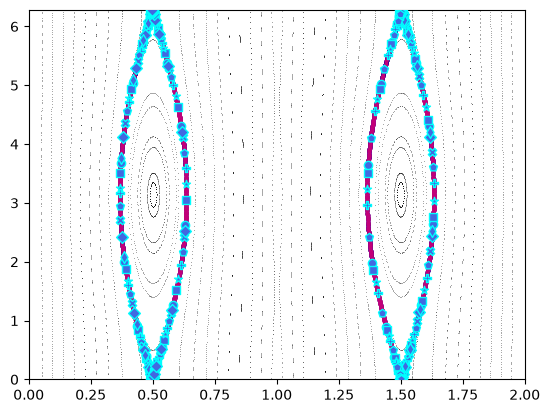

In [47]:
fig, ax = pplot.plot(marker=".", s=0.5, xlim=[.0, 2.], ylim=[0., 2*np.pi], plottype=None)

manifold1.plot("both", ax=ax)
manifold1.plot_clinics(ax=ax)
manifold2.plot("both", ax=ax)
manifold2.plot_clinics(ax=ax)
manifold3.plot("both", ax=ax)
manifold3.plot_clinics(ax=ax)
manifold4.plot("both", ax=ax)
manifold4.plot_clinics(ax=ax)
# ax.legend(loc="upper left")